<a href="https://colab.research.google.com/github/Phantomtester/PyTorch/blob/main/PyTorch_Workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
from torch import nn # nn contains all the Pytorch's building blocks of neural network
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print(torch.__version__)


2.11.0+cpu


## Data preparing and loading
ML game has two parts :- 1. Turn data into numbers,  2. Build models to learn pattern in number.

We will use linear regression algorithm to make straight line with known parameters.


In [ ]:
# Create * known parameter
weight = 0.7
bias = 0.3

# Generating the Features
start = 0
end = 1
step = 0.02
target = torch.arange(start, end, step).unsqueeze(dim=1)

In [ ]:
# Create labels
labels = weight * target + bias

In [ ]:
target[:10], labels[:10]   # Inspecting the First 10 Samples

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [ ]:
len(target), len(labels)

(50, 50)

In [ ]:
# Splitting data into training and test sets.
train_split = int(0.8 * len(target))

target_train, labels_train = target[:train_split], labels[:train_split]
target_test, labels_test = target[train_split:], labels[train_split:]

len(target_train), len(labels_train), len(target_test), len(labels_test)

(40, 40, 10, 10)

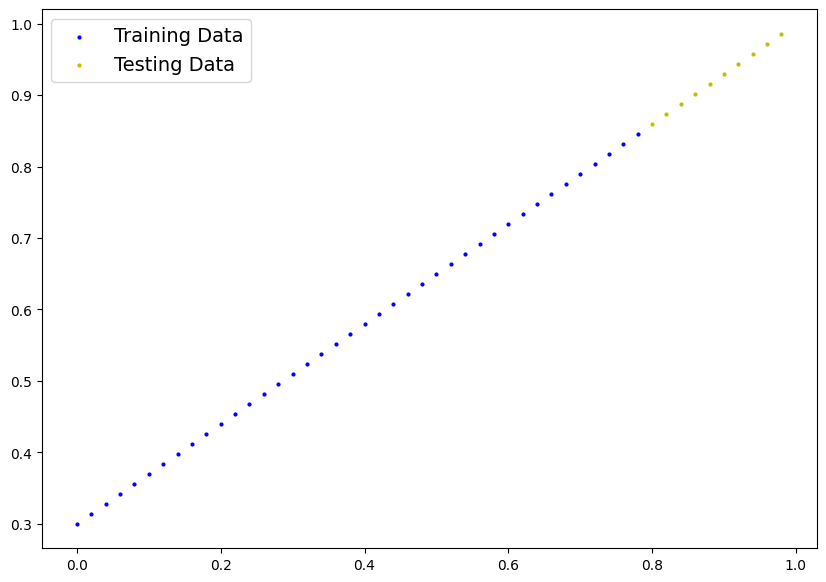

In [ ]:
# Visualizing the data

def plot_prediction (train_data = target_train,
                     train_labels = labels_train,
                     test_data = target_test,
                     test_labels = labels_test,
                     predictions=None):
  plt.figure(figsize=(10,7))

  # Plot training data in blue
  plt.scatter(train_data, train_labels, c="b", s=4, label="Training Data")

  # Plot test data in green
  plt.scatter(test_data, test_labels, c="y", s=4, label="Testing Data")

  if predictions is not None:
    plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")


  plt.legend(prop={"size": 14});

plot_prediction()


In [ ]:
# Creating Linear Regression model class
from torch import nn
class LinearRegressionModel(nn.Module):   # <-- Almost Everything in pytorch inherits from nn module
  def __init__(self):
    super().__init__()
    self.weights = nn.Parameter(torch.randn(1,         # <-- Start with random weight and try to adjust it to ideal weight
                                            dtype=torch.float),       # <--- pytorch loves float32 data
                                requires_grad=True)         # <-- this parameter will be updated via gradient descent
    self.bias = nn.Parameter(torch.randn(1,
                                         dtype=torch.float),
                             requires_grad=True)

  # Forward method to define computation in model
  def forward(self, x: torch.Tensor) -> torch.tensor:         # <-- x is input data
    return self.weights * x + self.bias




## PyTorch Model building Essentials
1- torch.nn -- contains all the parts (layers, loss functions, operations)   needed to construct a machine learning model.

2- torch.nn.Module -- base class of all neural network modules, If you subclass it, you should overwrite forward()

3- torch.nn.Parameter -- Special PyTorch tensors that store learnable values. These are the internal knobs and dials the model adjusts as it learns.

4- def forward() -- It defines the exact math formula or path input data takes to produce a prediction.

5- torch.optim -- Contains optimization algorithms.

6- torch.utils.data.Dataset -- A structure that holds and links your inputs (features) with their correct answers (labels).

7- torch.utils.data.DataLoader -- Instead of feeding all your data to the computer at once (which causes memory crashes), the DataLoader serves your data in small, bite-sized batches (e.g., 32 items at a time) and shuffles them for training.

In [ ]:
# Checking content of our model
# Create a random seed
torch.manual_seed(42)

# Create a instance of the model
model_0 = LinearRegressionModel()

# Check the state of the model
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [ ]:
# List the name of parameter
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [ ]:
# Ideal parameter values
weight, bias

(0.7, 0.3)

In [ ]:
# Making prediction using torch.inference_mode()
with torch.inference_mode():
  y_preds = model_0(target_test)
y_preds

tensor([[0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

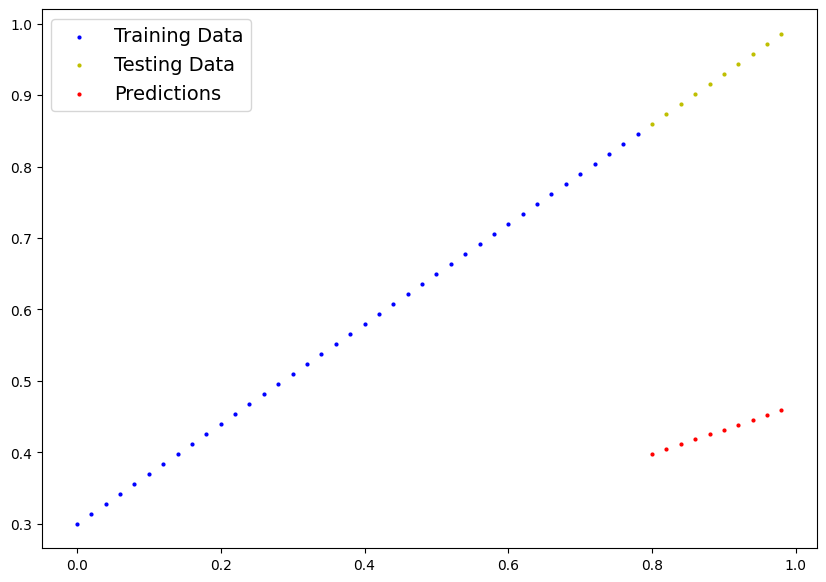

In [ ]:
plot_prediction(predictions= y_preds)

In [ ]:
y_preds1 = model_0(target_train)
y_preds1

tensor([[0.1288],
        [0.1355],
        [0.1423],
        [0.1490],
        [0.1557],
        [0.1625],
        [0.1692],
        [0.1759],
        [0.1827],
        [0.1894],
        [0.1961],
        [0.2029],
        [0.2096],
        [0.2163],
        [0.2231],
        [0.2298],
        [0.2366],
        [0.2433],
        [0.2500],
        [0.2568],
        [0.2635],
        [0.2702],
        [0.2770],
        [0.2837],
        [0.2904],
        [0.2972],
        [0.3039],
        [0.3106],
        [0.3174],
        [0.3241],
        [0.3308],
        [0.3376],
        [0.3443],
        [0.3510],
        [0.3578],
        [0.3645],
        [0.3712],
        [0.3780],
        [0.3847],
        [0.3914]], grad_fn=<AddBackward0>)

In [ ]:
# The key difference between these two code blocks is gradient tracking during model prediction.
# We can also use torch.no_grad() in place of torch.inference_mode()

## Train Model
The main idea of train model is to move from poor prediction to accurate prediction of outputs.
One way to measure the how poor or inaccurate model has predicted is to use loss function. Lower loss function is better.

Things we need to train:

**Loss function** is also called criterion or cost function.

**Optimizer** is responsible for updating your model's parameters (weights and biases) to minimize the loss function during training.

And specifically for Pytorch we need:


*   A Training loop
*   A Testing loop



In [ ]:
# Checking model's parameter. --> ( parameter is the value that model sets itself.)
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [ ]:
# Set up a loss function
loss_fn = nn.L1Loss()
loss_fn

L1Loss()

In [ ]:
# Set up a Optimizer ( currently using SGD)
opt_fn = torch.optim.SGD(params=model_0.parameters(),
                         lr=0.01)  # --> lr = learning rate ( most important hyperparameter a engineer can set.)

## Building a training loop in Pytorch.
PyTorch Training Loop Steps

 0. Loop through the data -->   Run the training process for a set number of rounds (epochs) over your dataset.

 1. Forward pass (forward propagation) -->  Pass your input data through the model using its forward() method to make predictions.

 2. Calculate the loss -->  Compare the model's predictions against the actual correct answers (ground truth) to see how wrong the model is.

 3. Zero the gradients (optimizer.zero_grad()) -->  Reset the stored gradients from the previous round back to zero so they don't stack up.

 4. Loss backward (backpropagation)  -->  Work backward through the network to figure out how much each parameter (weight) contributed to the total error.

 5. Optimizer step (gradient descent)  -->  Tweak and update the model's parameters using the optimizer to improve future predictions and lower the loss.

In [ ]:
# An epoch is one loop through data
epochs = 1

# loop through data
for epoch in range(epochs):
  model_0.train()   # Set the model to training  -- train mode sets all parameters that require gradient to require gradient

  model_0.eval()   # Turns off gradient tracking

  y_pred = model_0(target_train)   # Forward pass

  loss = loss_fn(y_pred, target_train)  # Calculate the loss
  print(f"Loss: {loss}")

 # optimizer.zero_grad()  # Clears (zero ) the accumlated gradient

  loss.backward()  # Performs backpropagation to calculates the gradients (the direction and amount of change needed) for every parameter in your model that contributed to the final loss.

 # optimizer.step()  # It takes the gradients calculated by loss.backward() and actually updates your model's weights and biases to reduce the loss.

  # Testing
  model_0.eval()


Loss: 0.16443711519241333


In [ ]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [ ]:
weight, bias

(0.7, 0.3)

In [ ]:
# 1. Setup Loss Function (e.g., L1Loss or MSELoss)
loss_fn = torch.nn.L1Loss()

# 2. Setup Optimizer (e.g., Stochastic Gradient Descent)
optimizer = torch.optim.SGD(params=model_0.parameters(),
                            lr=0.01)  # adjust learning rate as needed

In [ ]:
# Writing testing loop code.

torch.manual_seed(42)
epochs = 100

# Loop thorugh data
for epoch in range(epochs):
    model_0.train()

# Forward pass
    y_pred = model_0(target_train)

# Calculate loss
    loss = loss_fn(y_pred, labels_train)

# Reset Gradients
    optimizer.zero_grad()

# Backpropagation
    loss.backward()

# Update Parameters
    optimizer.step()

# Testing
    model_0.eval()
    with torch.inference_mode():
      test_pred = model_0(target_test)       # Forward pass
      test_loss = loss_fn(test_pred, labels_test)   # calculate loss

# Print
    if epoch % 10 == 0:
      print(f"Epoch: {epoch} | Loss: {loss} | Test Loss: {test_loss}")
      print(model_0.state_dict())



Epoch: 0 | Loss: 0.31288138031959534 | Test Loss: 0.48106518387794495
OrderedDict({'weights': tensor([0.3406]), 'bias': tensor([0.1388])})
Epoch: 10 | Loss: 0.1976713240146637 | Test Loss: 0.3463551998138428
OrderedDict({'weights': tensor([0.3796]), 'bias': tensor([0.2388])})
Epoch: 20 | Loss: 0.08908725529909134 | Test Loss: 0.21729660034179688
OrderedDict({'weights': tensor([0.4184]), 'bias': tensor([0.3333])})
Epoch: 30 | Loss: 0.053148526698350906 | Test Loss: 0.14464017748832703
OrderedDict({'weights': tensor([0.4512]), 'bias': tensor([0.3768])})
Epoch: 40 | Loss: 0.04543796554207802 | Test Loss: 0.11360953003168106
OrderedDict({'weights': tensor([0.4748]), 'bias': tensor([0.3868])})
Epoch: 50 | Loss: 0.04167863354086876 | Test Loss: 0.09919948130846024
OrderedDict({'weights': tensor([0.4938]), 'bias': tensor([0.3843])})
Epoch: 60 | Loss: 0.03818932920694351 | Test Loss: 0.08886633068323135
OrderedDict({'weights': tensor([0.5116]), 'bias': tensor([0.3788])})
Epoch: 70 | Loss: 0.03

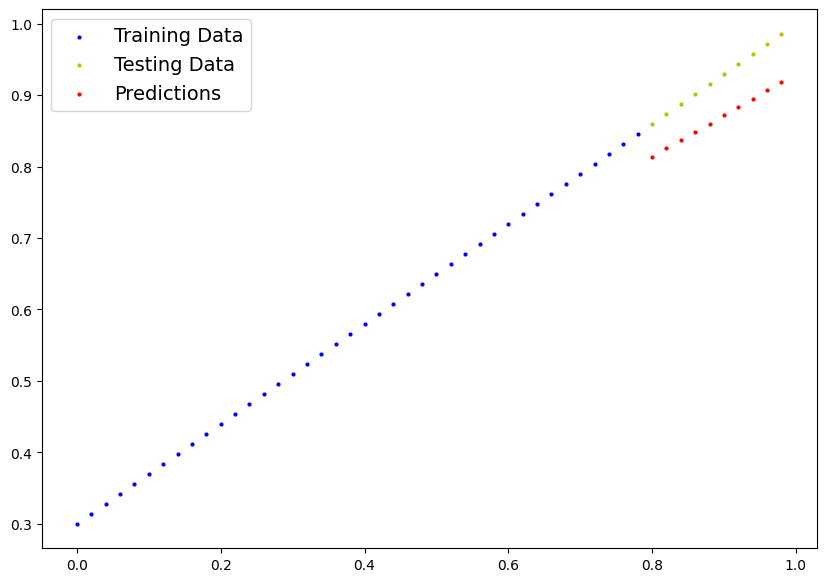

In [ ]:
plot_prediction(predictions=test_pred)

In [ ]:
# Pass the data through the model for a number of epochs (e.g. 100) pochs):
for epoch in range(epochs):

    ### Training loop code here ###

    ### Testing starts ###

    # Put the model in evaluation mode
    model_0.eval()

    # Turn on inference mode context manager
    with torch.inference_mode():
        # 1. Forward pass on test data
        test_pred = model_0(target_test)

        # 2. Caculate loss on test data
        test_loss = loss_fn(test_pred, labels_test)

    # Print out what's happening every 10 epochs
    if epoch % 10 == 0:
#        epoch_count.append(epoch)
#        train_loss_values.append(loss)
#        test_loss_values.append(test_loss)
        print(f"Epoch: {epoch} | MAE Train Loss: {loss} | MAE Test Loss: {test_loss} ")

Epoch: 0 | MAE Train Loss: 0.02479521557688713 | MAE Test Loss: 0.05687814950942993 
Epoch: 10 | MAE Train Loss: 0.02479521557688713 | MAE Test Loss: 0.05687814950942993 
Epoch: 20 | MAE Train Loss: 0.02479521557688713 | MAE Test Loss: 0.05687814950942993 
Epoch: 30 | MAE Train Loss: 0.02479521557688713 | MAE Test Loss: 0.05687814950942993 
Epoch: 40 | MAE Train Loss: 0.02479521557688713 | MAE Test Loss: 0.05687814950942993 
Epoch: 50 | MAE Train Loss: 0.02479521557688713 | MAE Test Loss: 0.05687814950942993 
Epoch: 60 | MAE Train Loss: 0.02479521557688713 | MAE Test Loss: 0.05687814950942993 
Epoch: 70 | MAE Train Loss: 0.02479521557688713 | MAE Test Loss: 0.05687814950942993 
Epoch: 80 | MAE Train Loss: 0.02479521557688713 | MAE Test Loss: 0.05687814950942993 
Epoch: 90 | MAE Train Loss: 0.02479521557688713 | MAE Test Loss: 0.05687814950942993 


## Saving the model in Pytorch

PyTorch provides three primary methods to serialize, save, and restore model parameters and architecture state to and from disk.

1- torch.save(): Serializes and saves a PyTorch object (such as a model's parameter dictionary or the entire model) to a file using Python's pickle utility.

2- torch.load(): Reads and deserializes a saved PyTorch file back into memory from disk.

3- torch.nn.Module.load_state_dict(): Takes a loaded parameter dictionary and applies those saved weights and biases directly onto an initialized PyTorch model class instance.


A state_dict is a standard Python OrderedDict that maps each layer or parameter in a neural network to its learnable weight and bias tensors.


In [ ]:
# Saving our PyTorch model
from pathlib import Path

# 1. Create models directory
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# 2. Create model save path
MODEL_NAME = "01_pytorch_workflow_model_0.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# 3. Save the model state dict
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model_0.state_dict(),
           f=MODEL_SAVE_PATH)

Saving model to: models/01_pytorch_workflow_model_0.pth


## Loading Model in Pytorch

In [ ]:
# Check original model state_dict
model_0.state_dict()

# To load in a saved state_dict we have to instantiate a new instance of our model class
loaded_model_0 = LinearRegressionModel()

# Load the saved state_dict of model_0 (this will update the new instance with updated parameters)
loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH))

# Verify loaded model state_dict
loaded_model_0.state_dict()

OrderedDict([('weights', tensor([0.5784])), ('bias', tensor([0.3513]))])

## Putting all together

In [ ]:
# Creat Data using Linear regression formula y = weight * X + Bias
weight = 0.7
bias = 0.3

# Create range value
start = 0
end = 1
step = 0.02

# Create X and Y
X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias
X[:10], y[:10]



(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [ ]:
# Split the data
train_split = int(0.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]
len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

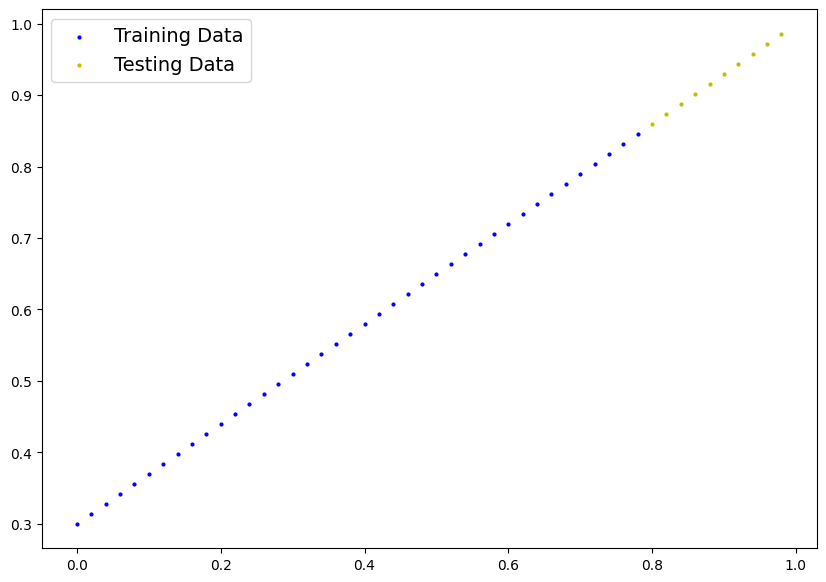

In [ ]:
# Plot the data
plot_prediction(X_train, y_train, X_test, y_test)


## Building a Pytorch Linear Model

In [ ]:
# Create a model by subclassing nn.module
class LinearRegressionModelV2 (nn.Module):
  def __init__(self):
    super().__init__()
    # use nn.linear for creating model parameter
    self.linear_layer = nn.Linear(in_features=1,
                                  out_features=1)

  def forward(self, x: torch.Tensor) -> torch.Tensor:    # Forward Computation
    return self.linear_layer(x)

# Set the manual seed
torch.manual_seed(42)

# Create an instance of the model
model_1 = LinearRegressionModelV2()
model_1, model_1.state_dict()


(LinearRegressionModelV2(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

In [ ]:
# Checking model current device
next(model_1.parameters()).device

device(type='cpu')

In [ ]:
# Set Model to target device
model_1.to(device="cuda") if torch.cuda.is_available() else model_1.to(device="cpu")
next(model_1.parameters()).device

device(type='cpu')

## Training of Model

For training we need :

1- Loss function

2- Optimizer

3- Training loop

4- Testing loop

In [ ]:
# Setting up loss function
loss_fn = nn.L1Loss()

# Setting up optimizer
optimizer = torch.optim.SGD(params=model_1.parameters(),
                            lr=0.01)

# training loop

torch.manual_seed(42)

epochs = 100

for epoch in range(epochs):
  model_1.train()

  # Forward pass
  y_pred = model_1(X_train)

  # Calculate the loss
  loss = loss_fn(y_pred, y_train)

  # Optimizer zero grad
  optimizer.zero_grad()

  # Backpropagation
  loss.backward()

  # Optimizer step
  optimizer.step()

  # Evaluation
  model_1.eval()
  with torch.inference_mode():
    test_pred = model_1(X_test)
    test_loss = loss_fn(test_pred, y_test)

  if epoch % 10 == 0:
    print(f"Epoch: {epoch} | Loss: {loss} | Test Loss: {test_loss}")
    print(model_1.state_dict())


Epoch: 0 | Loss: 0.5551779866218567 | Test Loss: 0.5739762187004089
OrderedDict({'linear_layer.weight': tensor([[0.7606]]), 'linear_layer.bias': tensor([0.8200])})
Epoch: 10 | Loss: 0.4399680495262146 | Test Loss: 0.4392663538455963
OrderedDict({'linear_layer.weight': tensor([[0.7216]]), 'linear_layer.bias': tensor([0.7200])})
Epoch: 20 | Loss: 0.3247582018375397 | Test Loss: 0.30455657839775085
OrderedDict({'linear_layer.weight': tensor([[0.6826]]), 'linear_layer.bias': tensor([0.6200])})
Epoch: 30 | Loss: 0.20954827964305878 | Test Loss: 0.16984674334526062
OrderedDict({'linear_layer.weight': tensor([[0.6436]]), 'linear_layer.bias': tensor([0.5200])})
Epoch: 40 | Loss: 0.09433844685554504 | Test Loss: 0.03513689711689949
OrderedDict({'linear_layer.weight': tensor([[0.6046]]), 'linear_layer.bias': tensor([0.4200])})
Epoch: 50 | Loss: 0.023886386305093765 | Test Loss: 0.04784906655550003
OrderedDict({'linear_layer.weight': tensor([[0.5872]]), 'linear_layer.bias': tensor([0.3525])})
Epo

In [ ]:
model_1.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.6691]])),
             ('linear_layer.bias', tensor([0.3130]))])

## Making and evaluating Predictions

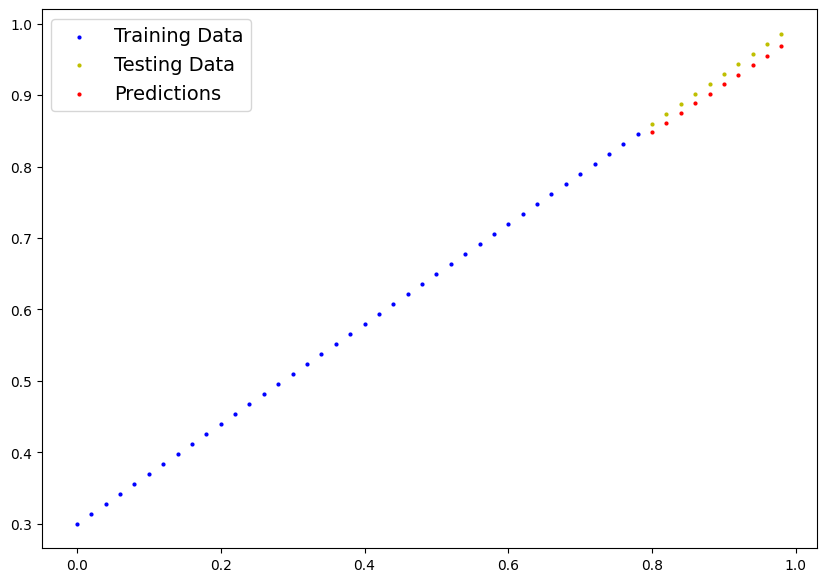

In [ ]:
# Turn model into evalation mode
model_1.eval()

# Make predictions
with torch.inference_mode():
  y_preds = model_1(X_test)

# Plot predictions
plot_prediction(predictions=y_preds)